# Machine learning guided variable selection for Max CSP
## MAAI801 completed mini project
This notebook explores the supplied training data, tunes Decision Tree and Random Forest regressors using instance-grouped validation, locks a model, and compares one-step decisions on held-out instances. The data and constraint/mutation helpers are supplied by the course. AI assistance generated the analysis and draft explanations; the submitting team must review and understand them.

Run all cells in order. Keep the supplied data files beside this notebook, in `supplied/MAAI801_MaxCSP_Student_Package`, or upload the original student ZIP in Google Colab. Outputs are saved under `results/` and `figures/` in the current directory. No full genetic algorithm is implemented.

In [1]:
from pathlib import Path
import sys, zipfile, os
OUTPUT = Path.cwd()
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT / '.matplotlib_cache'))
candidates = [OUTPUT, OUTPUT/'MAAI801_MaxCSP_Student_Package', OUTPUT/'supplied'/'MAAI801_MaxCSP_Student_Package', OUTPUT.parent/'supplied'/'MAAI801_MaxCSP_Student_Package']
ROOT = next((p for p in candidates if (p/'candidate_dataset.csv').exists()), None)
if ROOT is None:
    for archive in OUTPUT.glob('*.zip'):
        with zipfile.ZipFile(archive) as z:
            if any(n.endswith('candidate_dataset.csv') for n in z.namelist()):
                z.extractall(OUTPUT)
                break
    ROOT = next((p.parent for p in OUTPUT.rglob('candidate_dataset.csv')), None)
if ROOT is None:
    raise FileNotFoundError('Upload the original course student ZIP or place the supplied files beside this notebook.')
ROOT = ROOT.resolve()
sys.path.insert(0, str(ROOT))
for name in ['results','figures']:
    (OUTPUT/name).mkdir(exist_ok=True)
print('Data directory:', ROOT)


Data directory: ./supplied/MAAI801_MaxCSP_Student_Package


In [2]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from maxcsp_tools import load_instances, candidate_features, evaluate_heuristic, evaluate_ml_selection

# ROOT is initialized by the setup cell above.
data = pd.read_csv(ROOT / 'candidate_dataset.csv')
states = pd.read_csv(ROOT / 'states.csv')
instances = load_instances(ROOT / 'instances.json')
FEATURES = ['variable_degree', 'variable_violations', 'template_percentage',
            'current_violations', 'current_satisfaction', 'num_constraints']
TARGET = 'improvement'
print('Dataset shape:', data.shape)
print('Number of instances:', data.instance_id.nunique())
print(data.groupby('split').size())
print(data.head().to_string(index=False))

from sklearn.model_selection import GroupShuffleSplit
train_df=data.loc[data['split'].eq('train')].copy()
test_df=data.loc[data['split'].eq('test')].copy()
splitter=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42)
idx_tr,idx_val=next(splitter.split(train_df,groups=train_df.instance_id))
fit_df=train_df.iloc[idx_tr].copy();val_df=train_df.iloc[idx_val].copy()
fit_ids=set(fit_df.instance_id);val_ids=set(val_df.instance_id);test_ids=set(test_df.instance_id)
assert fit_ids.isdisjoint(val_ids) and fit_ids.isdisjoint(test_ids) and val_ids.isdisjoint(test_ids)
assert (len(fit_df),len(val_df),len(test_df))==(5120,1280,1600)
assert data.groupby('state_id').size().eq(8).all()
assert data.groupby('instance_id').state_id.nunique().eq(5).all()
assert not train_df[FEATURES+[TARGET]].isna().any().any()
assert train_df[TARGET].ge(0).all()
manifest=pd.DataFrame([(i,p) for ids,p in [(fit_ids,'fit'),(val_ids,'validation'),(test_ids,'test')] for i in sorted(ids)],columns=['instance_id','partition']).sort_values('instance_id')
manifest.to_csv(OUTPUT/'results'/'split_manifest.csv',index=False)
bundle={'data':data,'train_df':train_df,'fit_df':fit_df,'val_df':val_df,'test_df':test_df,'states':states,'instances':instances,'manifest':manifest}
print('Instance groups:',manifest.partition.value_counts().to_dict())
print('Missing training feature/target values:',int(train_df[FEATURES+[TARGET]].isna().sum().sum()))
print('Duplicate candidate keys:',int(train_df.duplicated(['instance_id','state_id','variable_index']).sum()))


Matplotlib is building the font cache; this may take a moment.


Dataset shape: (8000, 11)
Number of instances: 200
split
test     1600
train    6400
dtype: int64
split instance_id     state_id  variable_index  variable_degree  variable_violations  template_percentage  current_violations  current_satisfaction  num_constraints  improvement
train   train_000 train_000_s0               0                2                    1                 50.0                   2                     7                9            1
train   train_000 train_000_s0               1                3                    0                  0.0                   2                     7                9            0
train   train_000 train_000_s0               2                2                    0                  0.0                   2                     7                9            0
train   train_000 train_000_s0               3                1                    0                  0.0                   2                     7                9            0
train   trai

Instance groups: {'fit': 128, 'test': 40, 'validation': 32}
Missing training feature/target values: 0
Duplicate candidate keys: 0


## Provided baseline demonstration — run before the ML tasks

This demonstration selects one test-independent **training state**, applies the percentage-based heuristic, and evaluates the selected variable. It is provided so you can understand the baseline. You must still build **both regression models** and complete the ML comparison yourselves.


In [3]:
# Provided baseline: one starting solution and one best-value modification.
s = states[states['split'] == 'train'].iloc[0]
inst = instances[s['instance_id']]
assignment = json.loads(s['assignment_json'])
from maxcsp_tools import n_violations, satisfaction, heuristic_select
print('Starting assignment:', assignment)
print('Before: violated =', n_violations(inst, assignment),
      ', satisfied =', satisfaction(inst, assignment))
selected = heuristic_select(inst, assignment)
result = evaluate_heuristic(inst, assignment)
print('Selected variable index:', selected, '(Python indices start at 0)')
print('Change:', result['old_value'], '→', result['new_value'])
print('After: violated =', result['violations_after'],
      ', satisfied =', result['satisfied_after'])
print('Actual one-step improvement:', result['improvement'])


Starting assignment: [3, 1, 2, 0, 3, 1, 1, 0]
Before: violated = 2 , satisfied = 7
Selected variable index: 0 (Python indices start at 0)
Change: 3 → 1
After: violated = 1 , satisfied = 8
Actual one-step improvement: 1


## Task 1 Explore the training data
One row represents one candidate variable in a current assignment. The target is the reduction in violations after the supplied best-value change of that variable. All records from one instance share a constraint structure, so validation splits keep them together. IDs, split labels, target, and post-mutation outcomes are excluded from predictive inputs.

,variable_degree,variable_violations,template_percentage,current_violations,current_satisfaction,num_constraints,improvement
count,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000
mean,3.659375,1.848437,49.147507,7.393750,7.243750,14.637500,0.775781
std,1.979242,1.610589,36.286832,5.258377,5.448071,6.757457,0.915328
min,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000
25%,2.000000,1.000000,16.666667,3.000000,3.000000,9.000000,0.000000
50%,4.000000,2.000000,50.000000,6.000000,6.000000,14.000000,1.000000
75%,5.000000,3.000000,80.000000,10.250000,11.000000,20.000000,1.000000
max,7.000000,7.000000,100.000000,25.000000,24.000000,28.000000,5.000000


Training target counts: {0: 3077, 1: 2084, 2: 911, 3: 257, 4: 67, 5: 4}
Zero improvement percentage: 48.078125


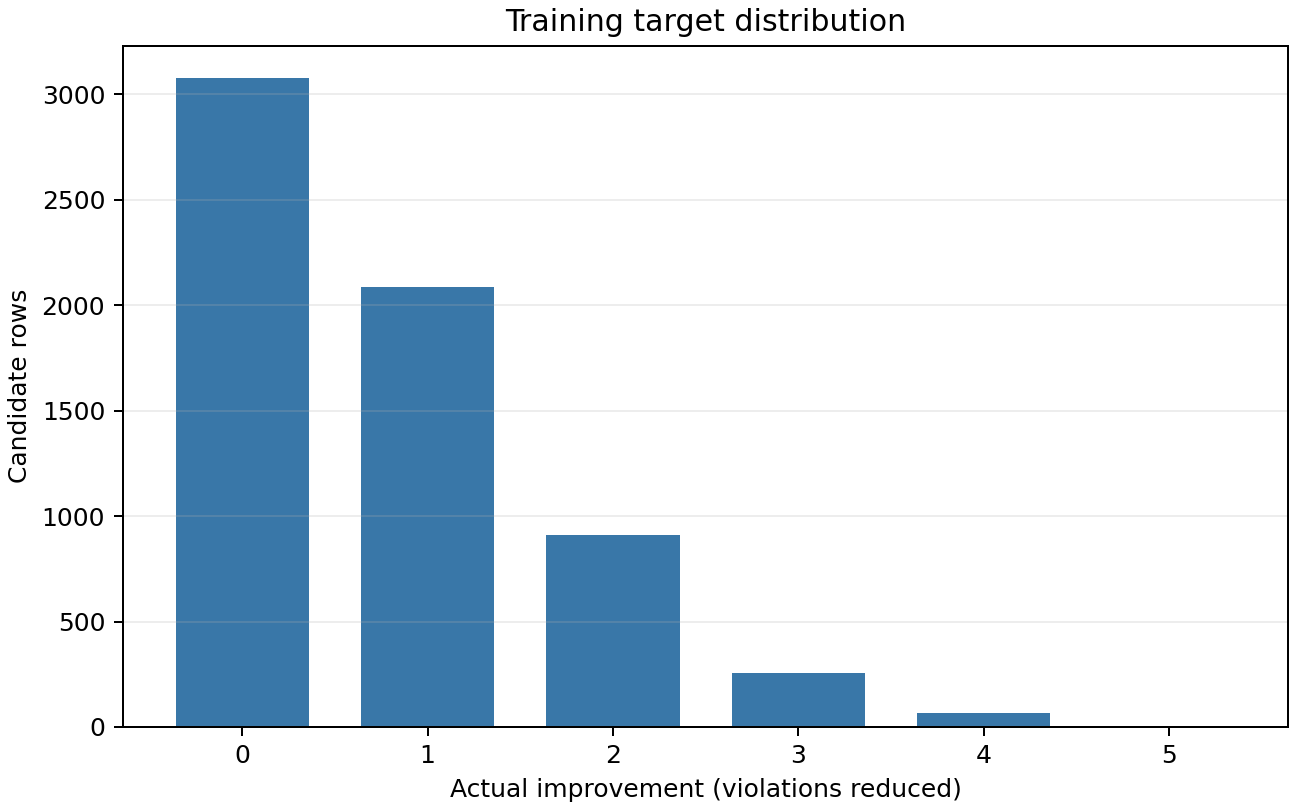

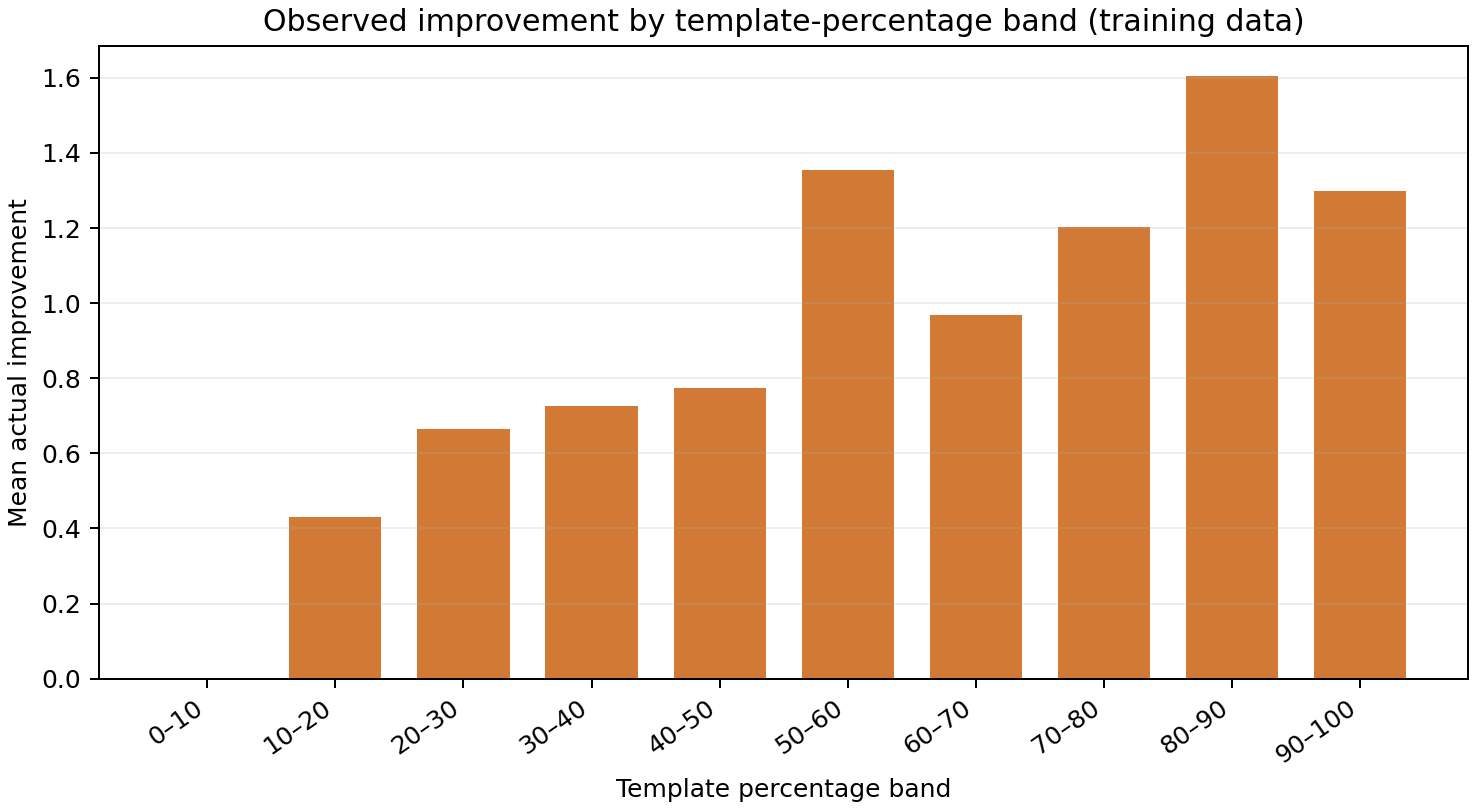

In [4]:
IDENTIFIERS=['instance_id','state_id','variable_index']
def training_eda(bundle: dict[str, object], output_root: str | Path) -> dict[str, object]:
    """Create EDA summaries and figures from the provided training rows only."""
    out = Path(output_root).resolve()
    (out / "figures").mkdir(parents=True, exist_ok=True)
    (out / "results").mkdir(parents=True, exist_ok=True)
    train = bundle["train_df"]
    # The provided held-out test partition is never read or summarized here.
    assert isinstance(train, pd.DataFrame)
    target_counts = train[TARGET].value_counts().sort_index()
    zero_rate = float(train[TARGET].eq(0).mean())
    train_features = train[FEATURES]
    ranges = pd.DataFrame({"min": train_features.min(), "max": train_features.max()})
    train_dup_keys = int(train.duplicated(IDENTIFIERS).sum())
    train_duplicate_rows = int(train.duplicated().sum())
    train_state_count = int(train["state_id"].nunique())

    # Figure 1: target distribution; counts are based only on train instances.
    fig, ax = plt.subplots(figsize=(7.2, 4.5), constrained_layout=True)
    ax.bar(target_counts.index.astype(int), target_counts.values, color="#3977a8", width=0.72)
    ax.set(title="Training target distribution", xlabel="Actual improvement (violations reduced)",
           ylabel="Candidate rows")
    ax.set_xticks(target_counts.index.astype(int))
    ax.grid(axis="y", alpha=0.22)
    fig.savefig(out / "figures" / "eda_target_distribution.png", dpi=180)
    plt.close(fig)

    # Figure 2: binned relationship between pre-mutation template percentage and target.
    bins = np.arange(0, 110, 10)
    labels = [f"{a}–{a+10}" for a in bins[:-1]]
    binned = train[["template_percentage", TARGET]].copy()
    binned["percentage_band"] = pd.cut(binned["template_percentage"], bins=bins,
                                        labels=labels, include_lowest=True, right=True)
    trend = binned.groupby("percentage_band", observed=False)[TARGET].agg(["mean", "count"])
    fig, ax = plt.subplots(figsize=(8.2, 4.5), constrained_layout=True)
    present = trend["count"].gt(0)
    ax.bar(np.arange(len(trend))[present], trend.loc[present, "mean"],
           color="#d27a35", width=0.72)
    ax.set(title="Observed improvement by template-percentage band (training data)",
           xlabel="Template percentage band", ylabel="Mean actual improvement")
    ax.set_xticks(np.arange(len(trend)), trend.index.astype(str), rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.22)
    fig.savefig(out / "figures" / "eda_improvement_by_template_percentage.png", dpi=180)
    plt.close(fig)

    return {"target_counts": target_counts, "zero_target_rate": zero_rate,
            "feature_ranges": ranges, "duplicate_key_rows": train_dup_keys,
            "duplicate_full_rows": train_duplicate_rows,
            "train_state_count": train_state_count,
            "binned_target": trend}
summary_eda=training_eda(bundle,OUTPUT)
display(train_df[FEATURES+[TARGET]].describe())
print('Training target counts:',summary_eda['target_counts'].to_dict())
print('Zero improvement percentage:',100*summary_eda['zero_target_rate'])
from IPython.display import Image,display
for filename in ['eda_target_distribution.png','eda_improvement_by_template_percentage.png']:
    display(Image(filename=str(OUTPUT/'figures'/filename)))


The target is concentrated at zero: 3,077 of 6,400 training candidates (48.1%) produce no strict improvement. Most positive gains are small. Percentage bands broadly track higher improvement, but the relationship is nonmonotonic, so percentage alone does not determine the best variable. Band means also depend on which candidates fall in each band and do not imply causation.

## Task 2 — Train a Decision Tree Regressor
Fit on the provided `train` instances. Evaluate on a group-wise validation subset of train instances first; reserve `test` for the final evaluation.


In [5]:
from typing import Sequence
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
MAX_DEPTH_GRID=(3,5,8,None)
MIN_SAMPLES_LEAF_GRID=(1,5,10)
RANDOM_STATE=42
def tune_tree(
    fit_df: pd.DataFrame,
    val_df: pd.DataFrame,
    features: Sequence[str],
    target: str,
) -> tuple[DecisionTreeRegressor, pd.DataFrame, dict[str, int | None]]:
    """Tune the declared grid and return its selected fit, table, and params.

    Validation MAE is minimized. Exact ties prefer a shallower maximum depth
    (with ``None`` ranked as unbounded/most complex), then a larger leaf size.
    """
    missing = (set(features) | {target}) - set(fit_df.columns)
    missing |= (set(features) | {target}) - set(val_df.columns)
    if missing:
        raise ValueError(f"Missing model columns: {sorted(missing)}")
    if fit_df.empty or val_df.empty:
        raise ValueError("Fit and validation partitions must both be non-empty")

    X_fit, y_fit = fit_df[list(features)], fit_df[target]
    X_val, y_val = val_df[list(features)], val_df[target]
    rows: list[dict[str, object]] = []
    for depth in MAX_DEPTH_GRID:
        for leaf_size in MIN_SAMPLES_LEAF_GRID:
            model = DecisionTreeRegressor(
                max_depth=depth,
                min_samples_leaf=leaf_size,
                random_state=RANDOM_STATE,
            )
            model.fit(X_fit, y_fit)
            mae = float(mean_absolute_error(y_val, model.predict(X_val)))
            rows.append({
                "max_depth": depth,
                "min_samples_leaf": leaf_size,
                "random_state": RANDOM_STATE,
                "validation_mae": mae,
            })

    table = pd.DataFrame(rows)
    # Stable explicit simplicity ordering for exact MAE ties.
    depth_rank = table["max_depth"].map(lambda depth: float("inf") if pd.isna(depth) else depth)
    order = table.assign(_depth_rank=depth_rank).sort_values(
        ["validation_mae", "_depth_rank", "min_samples_leaf"],
        ascending=[True, True, False], kind="mergesort",
    )
    selected = order.iloc[0]
    best_params: dict[str, int | None] = {
        "max_depth": None if pd.isna(selected["max_depth"]) else int(selected["max_depth"]),
        "min_samples_leaf": int(selected["min_samples_leaf"]),
        "random_state": RANDOM_STATE,
    }
    table["selected"] = (
        table["max_depth"].eq(best_params["max_depth"])
        & table["min_samples_leaf"].eq(best_params["min_samples_leaf"])
    )

    best_model = DecisionTreeRegressor(**best_params)
    best_model.fit(X_fit, y_fit)
    return best_model, table, best_params
dt_fit,dt_table,dt_params=tune_tree(fit_df,val_df,FEATURES,TARGET)
dt_table.to_csv(OUTPUT/'results'/'dt_validation.csv',index=False)
display(dt_table.sort_values('validation_mae'))
print('Selected Decision Tree:',dt_params)


,max_depth,min_samples_leaf,random_state,validation_mae,selected
8,8.0,10,42,0.518270,True
11,NaN,10,42,0.521205,False
7,8.0,5,42,0.522591,False
6,8.0,1,42,0.523920,False
10,NaN,5,42,0.531224,False
3,5.0,1,42,0.531444,False
4,5.0,5,42,0.531444,False
5,5.0,10,42,0.531780,False
9,NaN,1,42,0.561947,False
0,3.0,1,42,0.576804,False


Selected Decision Tree: {'max_depth': 8, 'min_samples_leaf': 10, 'random_state': 42}


## Task 3 — Train a Random Forest Regressor
Train, tune, and evaluate a random forest using the **same** fit/validation instance split. Compare with the Decision Tree.


In [6]:
from typing import Any
from sklearn.ensemble import RandomForestRegressor
def tune_forest(
    fit_df: pd.DataFrame,
    val_df: pd.DataFrame,
    features: list[str],
    target: str,
) -> tuple[RandomForestRegressor, pd.DataFrame, dict[str, Any]]:
    """Tune the declared modest grid and return fitted winner, scores, params.

    Exact MAE ties prefer fewer trees, a shallower tree, then larger leaves.
    ``max_depth=None`` is treated as deeper than every finite candidate.
    """
    grid = [
        {"n_estimators": n, "max_depth": depth, "min_samples_leaf": leaf}
        for n in (100, 200)
        for depth in (5, None)
        for leaf in (1, 5)
    ]
    records: list[dict[str, Any]] = []
    for params in grid:
        candidate = RandomForestRegressor(**params, random_state=42, n_jobs=-1)
        candidate.fit(fit_df[features], fit_df[target])
        predictions = candidate.predict(val_df[features])
        mae = float(mean_absolute_error(val_df[target], predictions))
        records.append({**params, "random_state": 42, "validation_mae": mae})

    validation = pd.DataFrame(records)
    # Stable and explicit deterministic tie resolution following the assignment.
    def tie_key(row: pd.Series) -> tuple[float, int, int, int]:
        depth = row["max_depth"]
        return (
            float(row["validation_mae"]),
            int(row["n_estimators"]),
            int(depth) if pd.notna(depth) else 10**9,
            -int(row["min_samples_leaf"]),
        )

    best_row = min((row for _, row in validation.iterrows()), key=tie_key)
    best_params = {
        "n_estimators": int(best_row["n_estimators"]),
        "max_depth": int(best_row["max_depth"]) if pd.notna(best_row["max_depth"]) else None,
        "min_samples_leaf": int(best_row["min_samples_leaf"]),
        "random_state": 42,
    }
    model = RandomForestRegressor(**best_params, n_jobs=-1)
    model.fit(fit_df[features], fit_df[target])
    validation = validation.sort_values(
        ["validation_mae", "n_estimators", "max_depth", "min_samples_leaf"],
        ascending=[True, True, True, False], na_position="last",
    ).reset_index(drop=True)
    return model, validation, best_params
rf_fit,rf_table,rf_params=tune_forest(fit_df,val_df,FEATURES,TARGET)
rf_table.to_csv(OUTPUT/'results'/'rf_validation.csv',index=False)
display(rf_table)
print('Selected Random Forest:',rf_params)


,n_estimators,max_depth,min_samples_leaf,random_state,validation_mae
0,200,NaN,5,42,0.514774
1,100,NaN,5,42,0.515608
2,200,5.0,5,42,0.522043
3,100,5.0,5,42,0.522501
4,200,5.0,1,42,0.522579
5,100,5.0,1,42,0.523060
6,100,NaN,1,42,0.537742
7,200,NaN,1,42,0.537744


Selected Random Forest: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'random_state': 42}


## Task 4 — Choose a model and evaluate on the held-out test set
After selecting your model using validation performance, evaluate MAE on held-out `test` instances **once**. Then compare ML-selected vs heuristic-selected variables on the exact same search states.


The search considers 12 tree settings and 8 forest settings at seed 42. Within-family exact ties prefer simpler configurations as encoded above. Select the family by validation MAE, preferring the Decision Tree on an exact tie. The Random Forest wins by a small validation margin of about 0.00350 violations. The margin alone does not demonstrate a robust advantage across new splits.

MODEL LOCKED: {"selection_basis": "validation MAE only; exact tie favors Decision Tree", "selected_model": "Random Forest", "dt_params": {"max_depth": 8, "min_samples_leaf": 10, "random_state": 42}, "rf_params": {"n_estimators": 200, "max_depth": null, "min_samples_leaf": 5, "random_state": 42}, "dt_validation_mae": 0.5182701392601263, "rf_validation_mae": 0.5147741198888189, "refit_policy": "Refit both locked configurations on all 160 training instances before final test."}


{
  "selection_basis": "validation MAE only; exact tie favors Decision Tree",
  "selected_model": "Random Forest",
  "dt_params": {
    "max_depth": 8,
    "min_samples_leaf": 10,
    "random_state": 42
  },
  "rf_params": {
    "n_estimators": 200,
    "max_depth": null,
    "min_samples_leaf": 5,
    "random_state": 42
  },
  "dt_validation_mae": 0.5182701392601263,
  "rf_validation_mae": 0.5147741198888189,
  "refit_policy": "Refit both locked configurations on all 160 training instances before final test.",
  "dt_test_mae": 0.4439339250580284,
  "rf_test_mae": 0.43654938549964534,
  "n_states": 200,
  "n_test_candidates": 1600,
  "n_test_instances": 40,
  "mean_starting_violations": 7.63,
  "heuristic_mean_improvement": 1.565,
  "ml_mean_improvement": 1.69,
  "heuristic_mean_violations_after": 6.065,
  "ml_mean_violations_after": 5.94,
  "wins": 23,
  "ties": 172,
  "losses": 5,
  "variable_disagreement_count": 40,
  "mean_gain_difference": 0.125,
  "instance_wins": 18,
  "instance

,model,validation_mae,test_mae
0,Decision Tree,0.518270,0.443934
1,Random Forest,0.514774,0.436549


,state_id,instance_id,violations_before,heuristic_selected_variable,heuristic_improvement,heuristic_violations_after,ml_selected_variable,ml_improvement,ml_violations_after,ml_outcome,variable_disagreement
0,test_000_s0,test_000,10,3,3,7,3,3,7,tie,False
1,test_000_s1,test_000,13,5,3,10,5,3,10,tie,False
2,test_000_s2,test_000,9,7,1,8,7,1,8,tie,False
3,test_000_s3,test_000,13,5,3,10,5,3,10,tie,False
4,test_000_s4,test_000,8,0,2,6,0,2,6,tie,False


,heuristic_improvement,ml_improvement,gain_difference
instance_id,,,
test_000,2.4,2.4,0.0
test_001,1.8,1.6,-0.2
test_002,2.4,2.8,0.4
test_003,2.2,2.4,0.2
test_004,1.2,1.6,0.4
test_005,1.4,1.6,0.2
test_006,1.0,0.8,-0.2
test_007,1.6,2.0,0.4
test_008,1.6,1.6,0.0


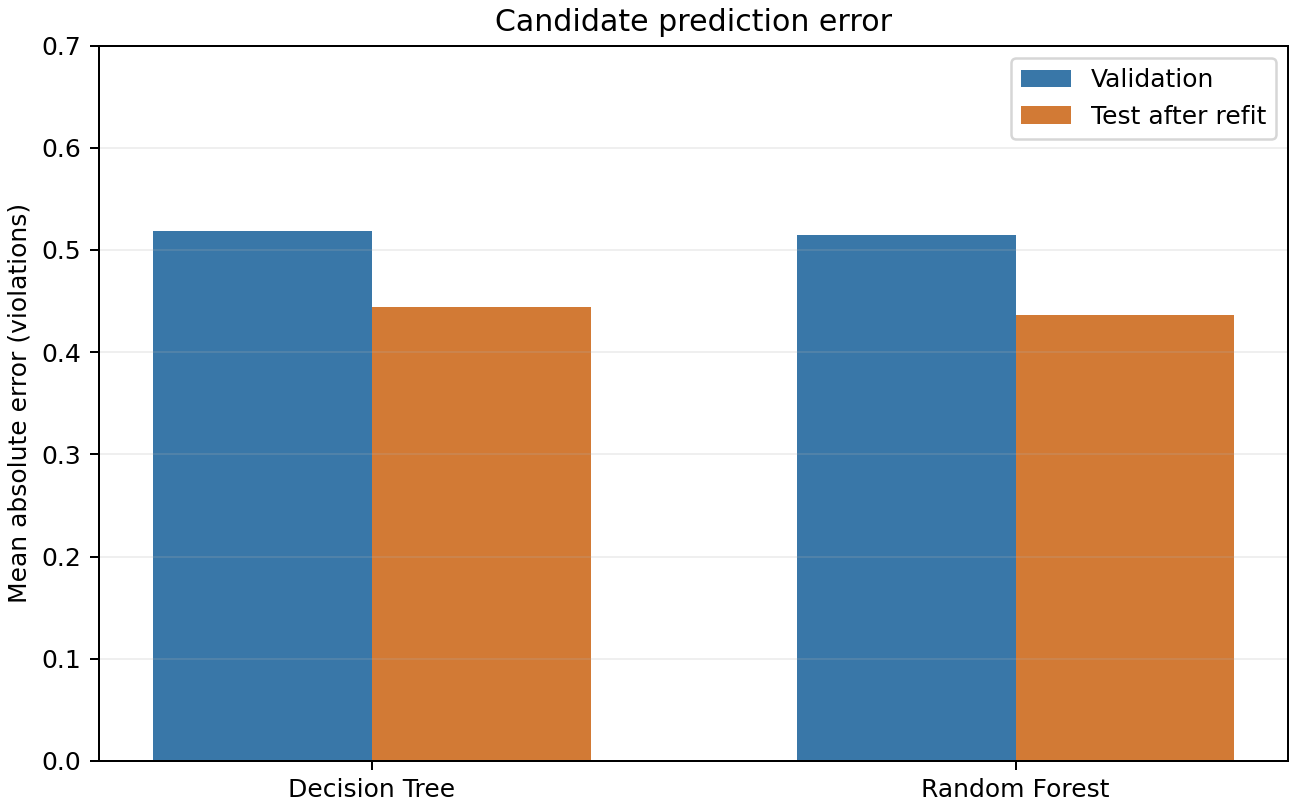

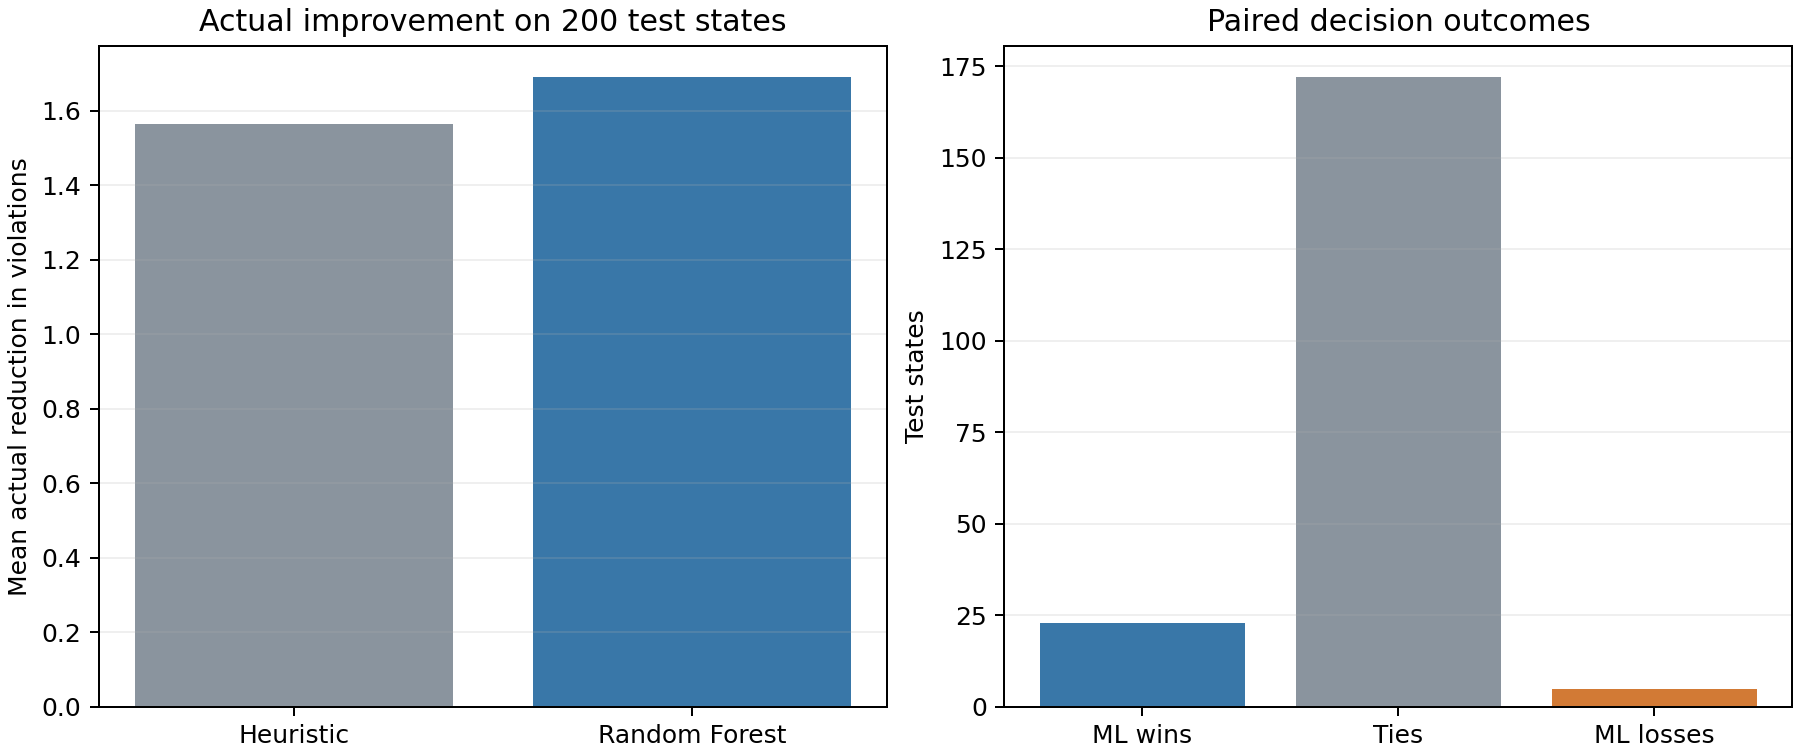

In [7]:
import platform,sklearn,matplotlib
PROJECT=OUTPUT
def compare_selection(states, instances, model, features):
    """Compare heuristic and ML one-step choices on the same input states.

    Parameters
    ----------
    states : pandas.DataFrame or iterable of mappings/records
        Rows need ``state_id``, ``instance_id``, and ``assignment_json``. The
        helper does not filter by ``split``; choose the allowed partition before
        calling it.
    instances : mapping
        ``instance_id -> instance`` as returned by ``load_instances``.
    model : fitted regressor
        Must implement ``predict(DataFrame)`` over the requested feature names.
    features : sequence[str]
        The six pre-mutation feature columns, in the same order used to fit the
        model. The target and identifiers must not be included.

    Returns
    -------
    pandas.DataFrame
        One row per input state, including shared starting violations,
        each method's selected variable, improvement, and remaining
        violations, the ML outcome (win/tie/loss versus heuristic improvement),
        and whether the methods selected different variables.

    Notes
    -----
    The comparison evaluates each method independently from a fresh copy of the
    same original assignment. It uses ``evaluate_heuristic`` and
    ``evaluate_ml_selection`` so tie-breaking and best-value mutation behavior
    match the supplied implementation exactly.
    """
    records = states.to_dict(orient="records") if isinstance(states, pd.DataFrame) else list(states)
    output = []
    for state in records:
        state_id = state["state_id"]
        instance_id = state["instance_id"]
        try:
            instance = instances[instance_id]
        except KeyError as exc:
            raise KeyError(f"No instance found for state {state_id!r}: {instance_id!r}") from exc

        raw_assignment = state["assignment_json"]
        assignment = json.loads(raw_assignment) if isinstance(raw_assignment, str) else list(raw_assignment)
        before = n_violations(instance, assignment)

        # Both supplied evaluators treat assignments as read-only and the
        # mutation helper copies them. Pass distinct copies to make the
        # same-starting-state contract explicit and robust to future changes.
        heuristic = evaluate_heuristic(instance, list(assignment))
        ml = evaluate_ml_selection(instance, list(assignment), model, features)

        if heuristic["violations_before"] != before or ml["violations_before"] != before:
            raise AssertionError(f"Selectors did not start from the original state {state_id!r}")
        h_gain = heuristic["improvement"]
        ml_gain = ml["improvement"]
        outcome = "win" if ml_gain > h_gain else "loss" if ml_gain < h_gain else "tie"
        output.append({
            "state_id": state_id,
            "instance_id": instance_id,
            "violations_before": before,
            "heuristic_selected_variable": heuristic["selected_variable"],
            "heuristic_improvement": h_gain,
            "heuristic_violations_after": heuristic["violations_after"],
            "ml_selected_variable": ml["selected_variable"],
            "ml_improvement": ml_gain,
            "ml_violations_after": ml["violations_after"],
            "ml_outcome": outcome,
            "variable_disagreement": (
                heuristic["selected_variable"] != ml["selected_variable"]
            ),
        })
    return pd.DataFrame(output, columns=[
        "state_id", "instance_id", "violations_before",
        "heuristic_selected_variable", "heuristic_improvement",
        "heuristic_violations_after", "ml_selected_variable",
        "ml_improvement", "ml_violations_after", "ml_outcome",
        "variable_disagreement",
    ])
dt_val=float(dt_table.validation_mae.min());rf_val=float(rf_table.validation_mae.min())
selected='Decision Tree' if dt_val<=rf_val else 'Random Forest'
lock={'selection_basis':'validation MAE only; exact tie favors Decision Tree',
      'selected_model':selected,'dt_params':dt_params,'rf_params':rf_params,
      'dt_validation_mae':dt_val,'rf_validation_mae':rf_val,
      'refit_policy':'Refit both locked configurations on all 160 training instances before final test.'}
(PROJECT/'results'/'model_selection_lock.json').write_text(json.dumps(lock,indent=2))
print('MODEL LOCKED:',json.dumps(lock),flush=True)
train_df=bundle['train_df'];test_df=bundle['test_df']
dt_model=DecisionTreeRegressor(**dt_params).fit(train_df[FEATURES],train_df[TARGET])
rf_model=RandomForestRegressor(**rf_params,n_jobs=-1).fit(train_df[FEATURES],train_df[TARGET])
models={'Decision Tree':dt_model,'Random Forest':rf_model};best_model=models[selected]
metrics=pd.DataFrame([{'model':name,'validation_mae':val,'test_mae':mean_absolute_error(test_df[TARGET],model.predict(test_df[FEATURES]))} for name,val,model in [('Decision Tree',dt_val,dt_model),('Random Forest',rf_val,rf_model)]])
test_states=bundle['states'].query("split == 'test'")
comparison=compare_selection(test_states,bundle['instances'],best_model,FEATURES)
assert len(comparison)==200 and comparison.state_id.is_unique
for prefix in ['heuristic','ml']:
 assert (comparison[f'{prefix}_improvement']==comparison.violations_before-comparison[f'{prefix}_violations_after']).all()
 assert comparison[f'{prefix}_improvement'].ge(0).all()
metrics.to_csv(PROJECT/'results'/'final_prediction_metrics.csv',index=False)
comparison.to_csv(PROJECT/'results'/'final_state_comparison.csv',index=False)
byinstance=comparison.groupby('instance_id')[['heuristic_improvement','ml_improvement']].mean()
byinstance['gain_difference']=byinstance.ml_improvement-byinstance.heuristic_improvement
byinstance.to_csv(PROJECT/'results'/'final_instance_comparison.csv')
counts=comparison.ml_outcome.value_counts().reindex(['win','tie','loss'],fill_value=0)
summary={**lock,'dt_test_mae':float(metrics.iloc[0].test_mae),'rf_test_mae':float(metrics.iloc[1].test_mae),'n_states':len(comparison),'n_test_candidates':len(test_df),'n_test_instances':40,'mean_starting_violations':float(comparison.violations_before.mean()),'heuristic_mean_improvement':float(comparison.heuristic_improvement.mean()),'ml_mean_improvement':float(comparison.ml_improvement.mean()),'heuristic_mean_violations_after':float(comparison.heuristic_violations_after.mean()),'ml_mean_violations_after':float(comparison.ml_violations_after.mean()),'wins':int(counts['win']),'ties':int(counts['tie']),'losses':int(counts['loss']),'variable_disagreement_count':int(comparison.variable_disagreement.sum()),'mean_gain_difference':float((comparison.ml_improvement-comparison.heuristic_improvement).mean()),'instance_wins':int(byinstance.gain_difference.gt(0).sum()),'instance_ties':int(byinstance.gain_difference.eq(0).sum()),'instance_losses':int(byinstance.gain_difference.lt(0).sum()),'environment':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__}}
assert summary['wins']+summary['ties']+summary['losses']==200
(PROJECT/'results'/'final_summary.json').write_text(json.dumps(summary,indent=2))
fig,ax=plt.subplots(figsize=(7.2,4.5),layout='constrained');x=np.arange(2);w=.34
ax.bar(x-w/2,metrics.validation_mae,w,label='Validation',color='#3977a8');ax.bar(x+w/2,metrics.test_mae,w,label='Test after refit',color='#d27a35')
ax.set_xticks(x,metrics.model);ax.set_ylabel('Mean absolute error (violations)');ax.set_title('Candidate prediction error');ax.legend();ax.set_ylim(0,.7);ax.grid(axis='y',alpha=.2)
fig.savefig(PROJECT/'figures'/'prediction_mae.png',dpi=180);plt.close(fig)
fig,axs=plt.subplots(1,2,figsize=(10,4.2),layout='constrained')
axs[0].bar(['Heuristic',selected],[summary['heuristic_mean_improvement'],summary['ml_mean_improvement']],color=['#8a949e','#3977a8'])
axs[0].set_ylabel('Mean actual reduction in violations');axs[0].set_title('Actual improvement on 200 test states')
axs[1].bar(['ML wins','Ties','ML losses'],counts.values,color=['#3977a8','#8a949e','#d27a35']);axs[1].set_ylabel('Test states');axs[1].set_title('Paired decision outcomes')
for ax in axs: ax.grid(axis='y',alpha=.2)
fig.savefig(PROJECT/'figures'/'selection_comparison.png',dpi=180);plt.close(fig)
print(json.dumps(summary,indent=2))

display(metrics)
display(comparison.head())
display(byinstance)
for filename in ['prediction_mae.png','selection_comparison.png']:
    display(Image(filename=str(OUTPUT/'figures'/filename)))


## Task 5 Reflection

1. **Prediction accuracy.** The Random Forest has lower validation MAE (0.514774 versus 0.518270) and test MAE (0.436549 versus 0.443934). Family selection used validation only. Both selected configurations were refit on all training instances before test scoring, so validation and test MAEs also differ in training-set size.
2. **Different variables.** ML chooses a different variable in 40/200 states (20%). Twelve of these disagreements tie on actual gain; different selected indices need not mean different outcomes.
3. **Actual outcomes.** ML wins in 23 states (11.5%), ties in 172 (86%), and loses in 5 (2.5%). Its mean gain is 1.690 versus 1.565, a descriptive advantage of 0.125 violations per state (about 8.0%). Remaining violations average 5.940 versus 6.065 from a shared starting mean of 7.630. On mean gain per instance, ML improves 18, ties 20, and worsens 2 of 40 test instances. The per-instance table above identifies them.
4. **MAE and choices.** MAE averages numerical errors over all candidates, whereas selection uses their within-state ordering. A low error on unselected variables can coexist with a wrong top choice. The available aggregate features can also give the same inputs to variables whose alternative domain values have different effects.
5. **Scope.** This supports a modest observed advantage for this frozen one-step selector on these held-out synthetic states. There is no population, crossover, repeated trajectory, or runtime measurement, so the evidence does not establish faster or better performance for a complete genetic algorithm.
6. **Limitations.** Instances contain only eight variables and four values. There is one grouped validation split, a small model search, and only 40 held-out problem instances with five correlated states each. No significance claim or generalization to all Max-CSPs is made. Future work could repeat the protocol on new instances or study ranking objectives without reusing this test set for tuning.

## References
Ben Othman, H., & Tagina, M. (2015). Guided Genetic Algorithm: A New Template Concept. *Procedia Computer Science, 60*, 1101–1108. https://doi.org/10.1016/j.procs.2015.08.156. Publisher abstract: https://www.sciencedirect.com/science/article/pii/S1877050915022838.

MAAI801 course assignment and supplied Max-CSP student package (2026). The original paper motivates percentage guidance; this notebook evaluates the course’s simplified supervised extension.
